# Buy Now, Pay Later (BNPL): Credit Risk Analysis

Course project: Python for Data Science DSBA 2025/2026. Dataset: Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv. Source: Kaggle: https://www.kaggle.com/datasets/shree0910/buy-now-and-pay-later-fintech-ml-dataset


### 1. Annotation

This project analyzes a Buy Now, Pay Later credit-risk dataset. The main goal is to study which customer and transaction characteristics are associated with default. In this dataset, default is shown by the variable `default_flag`: 0 means no default, and 1 means default.

Gleb Piskunov worked on dataset description, data quality checks, descriptive statistics, and the first overview visualizations. Artem Kostrichko worked on data transformation, detailed comparisons, hypothesis checking, and interpretation of statistical test results. Together, we chose the research focus, formulated the hypotheses, discussed the main findings, and wrote the final discussion.

### Imports

In this section, we import the main libraries for the project. Pandas is used for working with tables, numpy is used for numerical operations, matplotlib and seaborn are used for visualizations, and scipy.stats is used for hypothesis testing.


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

### 2. Dataset description

The dataset is related to fintech and credit risk in Buy Now, Pay Later services. Each row describes one user or transaction observation. The dataset includes customer characteristics, purchase information, repayment behavior, and risk-related variables.


In [24]:
# Load dataset
df = pd.read_csv('Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv')

print('Shape:', df.shape)
display(df.head())

Shape: (10345, 17)


,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment
0,1,56,Salaried,68529.50,552,5000.00,Electronics,12,13,1,0,8.49,Australia,2023-06-10,0.072961,165.2,Medium Risk
1,2,19,Student,7247.85,300,1073.23,Fashion,12,13,1,0,3.09,USA,2024-10-07,0.148076,266.0,High Risk
2,3,20,Self-Employed,41582.26,471,5000.00,Electronics,3,19,2,0,3.33,Australia,2023-04-05,0.120244,229.6,High Risk
3,4,21,Salaried,14423.46,300,4076.83,Sports,6,18,5,1,5.86,Germany,2023-06-24,0.282653,356.0,High Risk
4,5,43,Salaried,42845.50,512,5000.00,Electronics,9,0,0,0,7.36,India,2024-10-19,0.116698,135.2,High Risk


In [25]:
# Column types and basic structure
column_report = pd.DataFrame({
    'dtype': df.dtypes,
    'non_null_count': df.notna().sum(),
    'null_count': df.isna().sum(),
    'unique_values': df.nunique()
})

display(column_report)

,dtype,non_null_count,null_count,unique_values
user_id,int64,10345,0,10345
age,int64,10345,0,42
employment_type,str,10345,0,4
monthly_income,float64,10345,0,9984
credit_score,int64,10345,0,534
purchase_amount,float64,10345,0,4011
product_category,str,10345,0,5
bnpl_installments,int64,10345,0,4
repayment_delay_days,int64,10345,0,33
missed_payments,int64,10345,0,8


In [26]:
# Countries / locations and date range
print('Locations in the dataset:')
print(sorted(df['location'].unique()))

df['transaction_date'] = pd.to_datetime(df['transaction_date'])

print('\nDate range:')
print(df['transaction_date'].min(), '→', df['transaction_date'].max())

print('\nTarget variable values:')
print(df['default_flag'].value_counts().sort_index())
print('\nDefault rate:')
print(round(df['default_flag'].mean() * 100, 2), '%')

Locations in the dataset:
['Australia', 'Canada', 'Germany', 'India', 'UK', 'USA']

Date range:
2023-01-01 00:00:00 → 2024-12-31 00:00:00

Target variable values:
default_flag
0    6305
1    4040
Name: count, dtype: int64

Default rate:
39.05 %


**Dataset description discussion**

The dataset has 10,345 rows and 17 columns. It includes numerical fields such as age, monthly_income, credit_score, purchase_amount, repayment_delay_days, and risk_score. It also includes categorical fields such as employment_type, product_category, location, and customer_segment. The observations cover six locations: Australia, Canada, Germany, India, UK, and USA. The transaction dates are from January 1, 2023 to December 31, 2024.

The main target variable is default_flag. Since this variable contains only 0 and 1, it can be used as a binary indicator of default.

The first data quality investigation shows that the dataset is suitable for analysis. It has no missing values and no duplicated rows. The transaction_date column needs to be converted to datetime format, which is done in the data cleanup section. More detailed quality checks are shown later in the notebook.


### 3. Descriptive statistics for numerical fields

In this section, we calculate descriptive statistics for the main numerical variables. This gives a general overview of the scale, average values, and spread of the data.


In [27]:
numeric_cols = [
    'age',
    'monthly_income',
    'credit_score',
    'purchase_amount',
    'bnpl_installments',
    'repayment_delay_days',
    'missed_payments',
    'app_usage_frequency',
    'debt_to_income_ratio',
    'risk_score'
]

stats_table = pd.DataFrame({
    'mean': df[numeric_cols].mean(),
    'median': df[numeric_cols].median(),
    'std': df[numeric_cols].std(),
    'min': df[numeric_cols].min(),
    'max': df[numeric_cols].max()
})

stats_table.round(2)

,mean,median,std,min,max
age,38.56,39.00,12.13,18.0,59.00
monthly_income,35053.38,23800.52,27084.52,5000.0,145767.12
credit_score,448.18,403.00,136.52,300.0,850.00
purchase_amount,3979.40,5000.00,1500.83,100.0,5000.00
bnpl_installments,7.48,9.00,3.36,3.0,12.00
repayment_delay_days,8.74,9.00,6.78,0.0,33.00
missed_payments,1.02,1.00,1.00,0.0,7.00
app_usage_frequency,5.52,5.55,2.59,1.0,10.00
debt_to_income_ratio,0.18,0.14,0.12,0.0,0.72
risk_score,198.53,202.80,67.54,0.0,398.00


**Descriptive statistics discussion**

The table above shows that the numerical variables have different ranges. For example, `credit_score`, `monthly_income`, `purchase_amount`, and `risk_score` are measured on different scales. Because of this, later visualizations and group comparisons help us interpret the data more clearly.

### 4. Data cleanup

In this section, we check the quality of the dataset. We look for missing values, duplicated rows, incorrect values in the target variable, and possible logical problems in numerical columns.


In [28]:
display(df.isna().sum())

print('Duplicated rows:', df.duplicated().sum())
print('Duplicated user_id:', df['user_id'].duplicated().sum())

# Check data types after converting transaction_date
print('\nColumn types:')
print(df.dtypes)

# Check the target variable and impossible negative values
print('\ndefault_flag values:', sorted(df['default_flag'].unique()))
print('Negative purchase_amount:', (df['purchase_amount'] < 0).sum())
print('Negative monthly_income:', (df['monthly_income'] < 0).sum())
print('Negative repayment_delay_days:', (df['repayment_delay_days'] < 0).sum())

user_id                 0
age                     0
employment_type         0
monthly_income          0
credit_score            0
purchase_amount         0
product_category        0
bnpl_installments       0
repayment_delay_days    0
missed_payments         0
default_flag            0
app_usage_frequency     0
location                0
transaction_date        0
debt_to_income_ratio    0
risk_score              0
customer_segment        0
dtype: int64

Duplicated rows: 0
Duplicated user_id: 0

Column types:
user_id                          int64
age                              int64
employment_type                    str
monthly_income                 float64
credit_score                     int64
purchase_amount                float64
product_category                   str
bnpl_installments                int64
repayment_delay_days             int64
missed_payments                  int64
default_flag                     int64
app_usage_frequency            float64
location                           str
transaction_date        datetime64[us]
debt_to_income_ratio           float64
risk_score                     float64
customer_segment                   str
dtype: object

default_flag values: [np.int64(0), np.int64(1)]
Negative purchase_amount: 0
Negative monthly_income: 0
Negative repayment_delay_days: 0


In [29]:
# We keep a cleaned dataframe.
# No rows are removed because there are no missing values, no duplicated rows,
# and the checked numerical columns have no impossible negative values.
df_clean = df.copy()

print('Original shape:', df.shape)
print('Cleaned shape:', df_clean.shape)

Original shape: (10345, 17)
Cleaned shape: (10345, 17)


Data cleanup discussion

The dataset does not contain missing values or duplicated rows. The target variable default_flag contains only valid values, 0 and 1. The transaction_date column was converted to datetime format. Since no serious quality problems were found, we did not remove any rows. Because the cleanup is minimal, we create new columns later in the data transformation section.


### 5. Overview: plots for numerical fields

This section presents the main numerical variables with several plot types. The goal is to understand distributions, spreads, and visible patterns before moving to more detailed comparisons.


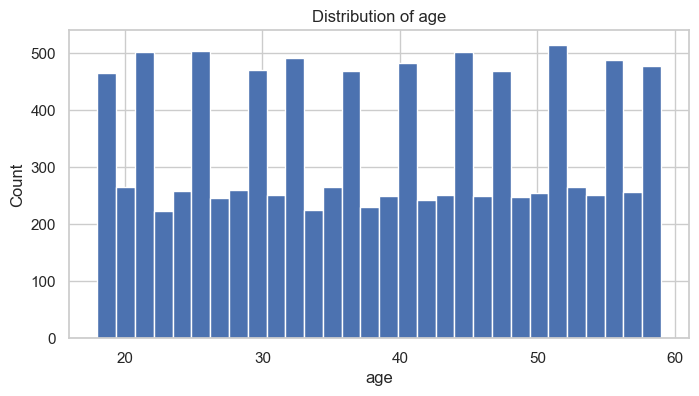

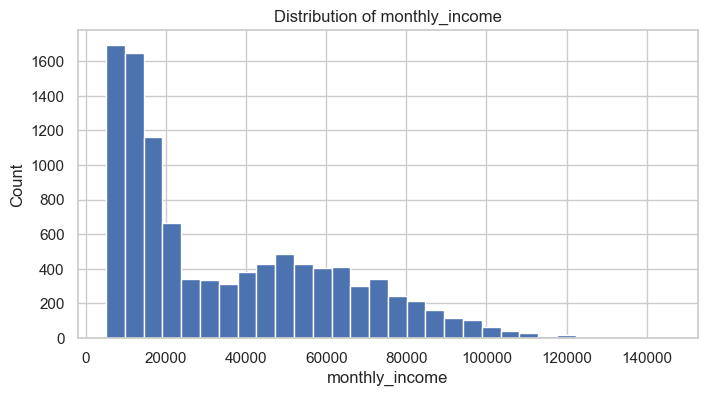

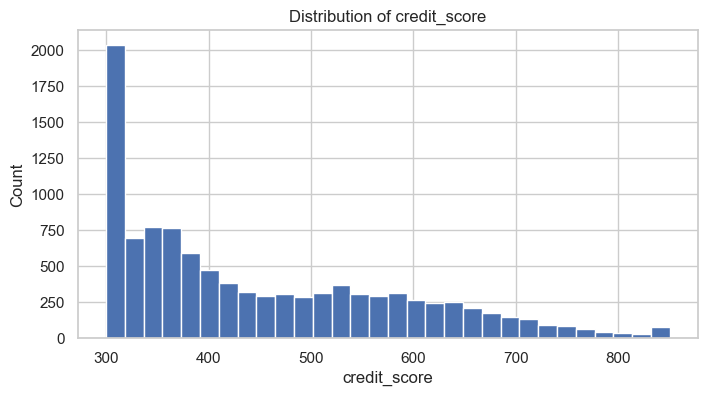

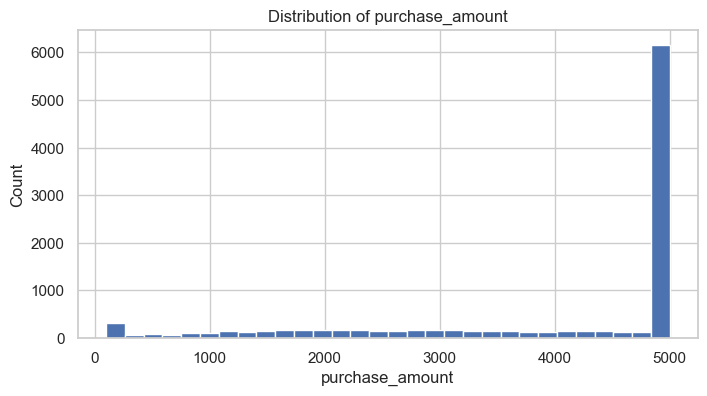

In [30]:
# Plot type 1: histograms for 4 numerical fields
overview_numeric = ['age', 'monthly_income', 'credit_score', 'purchase_amount']

for col in overview_numeric:
    plt.figure(figsize=(8, 4))
    plt.hist(df_clean[col], bins=30)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

* Histograms show that numerical variables are not distributed evenly. Most observations are concentrated in specific ranges, while some variables have long tails and possible outliers. This means that the dataset contains both typical clients/transactions and a smaller number of unusual cases that may require additional attention.

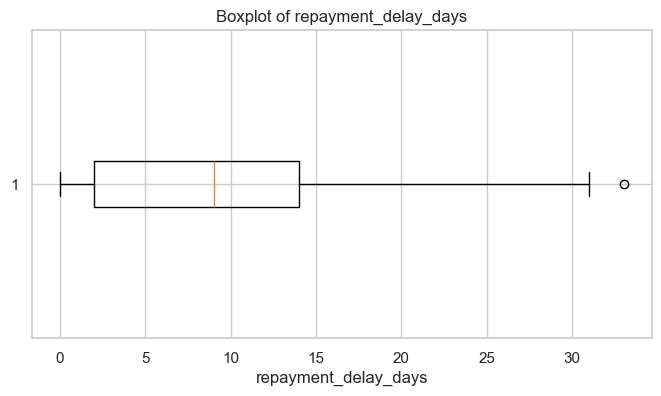

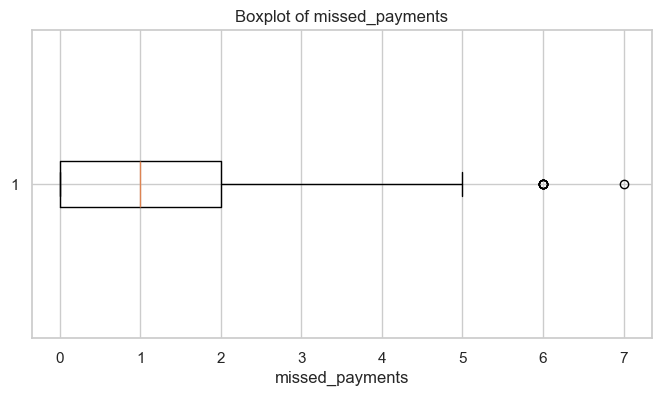

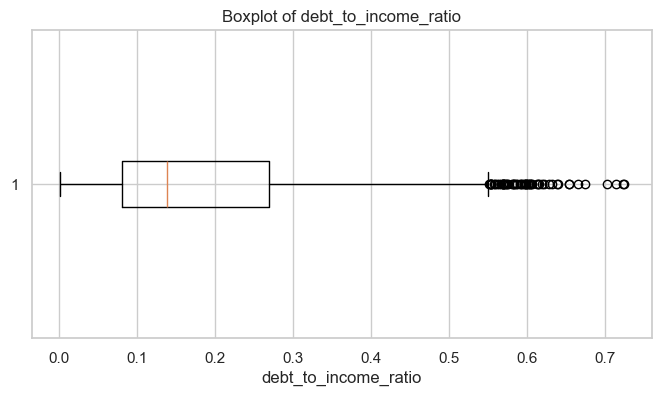

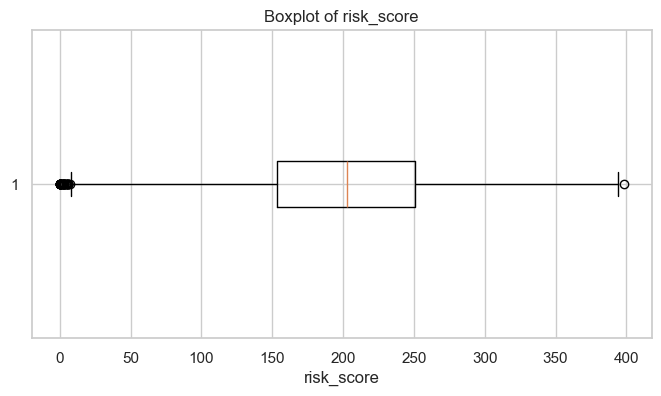

In [31]:
# Plot type 2: boxplots for repayment/risk numerical fields
boxplot_cols = ['repayment_delay_days', 'missed_payments', 'debt_to_income_ratio', 'risk_score']

for col in boxplot_cols:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df_clean[col].dropna(), vert=False)
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

* Boxplots show the spread of repayment and risk-related variables. Some variables have noticeable outliers, which means that a small number of clients differ strongly from the majority. These variables are worth checking in the detailed overview because they are directly connected with repayment behavior.

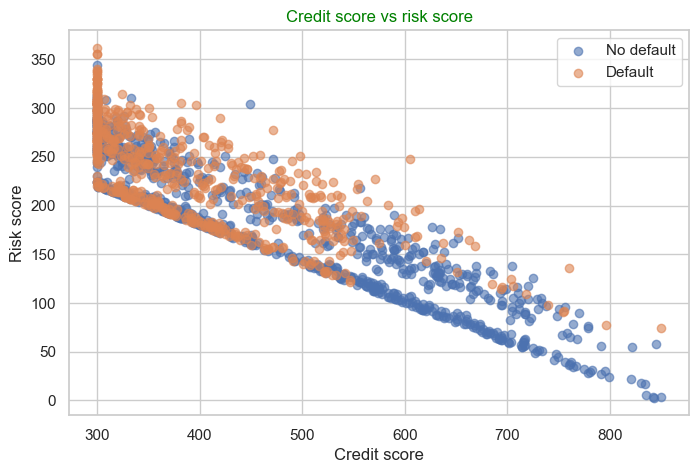

In [32]:
# Plot type 3: scatter plot for credit score and risk score
sample_df = df_clean.sample(1500, random_state=42)

plt.figure(figsize=(8, 5))

group_0 = sample_df[sample_df['default_flag'] == 0]
group_1 = sample_df[sample_df['default_flag'] == 1]

plt.scatter(group_0['credit_score'], group_0['risk_score'], alpha=0.6, label='No default')
plt.scatter(group_1['credit_score'], group_1['risk_score'], alpha=0.6, label='Default')

plt.title('Credit score vs risk score', color="green")
plt.xlabel('Credit score')
plt.ylabel('Risk score')
plt.legend()
plt.show()

* The scatter plot shows the relationship between credit score and risk score. Clients with lower credit scores tend to have higher risk scores more often. Default cases are more frequently located in the higher-risk area, but the groups still overlap. This means that these variables are useful, but they cannot perfectly separate default and non-default clients on their own.

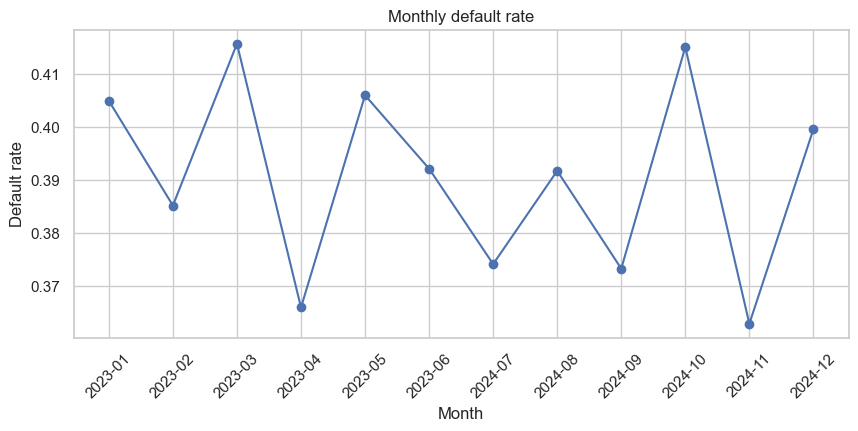

In [33]:
# Plot type 4: line plot over time

# We use string slicing to get year-month in a simple format.
df_clean['year_month'] = df_clean['transaction_date'].astype(str).str[:7]

monthly_default = df_clean.groupby('year_month')['default_flag'].mean()

plt.figure(figsize=(10, 4))
plt.plot(monthly_default.index, monthly_default.values, marker='o')
plt.title('Monthly default rate')
plt.xlabel('Month')
plt.ylabel('Default rate')
plt.xticks(rotation=45)
plt.show()

* The line plot shows that the default rate changes by month. Some months have higher default rates than others. There is no clear single trend, but monthly comparison is useful because it shows how stable or unstable the default rate is over time.

**Overview discussion**

The overview plots show the general distributions of the main numerical variables. Histograms help us understand variables such as income, credit score, and purchase amount. Boxplots show the spread of repayment and risk variables. The scatter plot gives a first visual impression of the relation between risk score, repayment delay, and default. The time plot checks whether the default rate changes across months.


### 6. More detailed overview: comparisons

In this section, we compare default rates and numerical patterns across different customer groups. These comparisons help us understand which groups have higher or lower default rates in the dataset.


,n_customers,default_rate_%
customer_segment,,
High Risk,7569,49.56
Medium Risk,2200,11.55
Low Risk,576,6.08


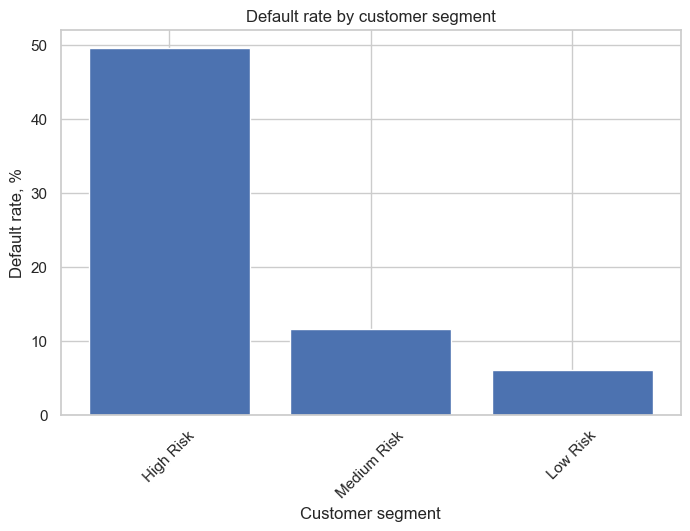

In [34]:
# Comparison 1: default rate by customer segment

segment_default = (
    df_clean
    .groupby('customer_segment')['default_flag']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
)

segment_default['mean'] = segment_default['mean'] * 100

segment_default = segment_default.rename(
    columns={
        'count': 'n_customers',
        'mean': 'default_rate_%'
    }
)

display(segment_default.round(2))

plt.figure(figsize=(8, 5))
plt.bar(segment_default.index, segment_default['default_rate_%'])
plt.title('Default rate by customer segment')
plt.xlabel('Customer segment')
plt.ylabel('Default rate, %')
plt.xticks(rotation=45)
plt.show()

* The default rate differs strongly across customer segments. The High Risk segment has a much higher default rate than the Medium Risk and Low Risk segments.

,n_customers,default_rate_%
employment_type,,
Unemployed,2632,48.67
Student,2531,48.56
Salaried,2632,32.71
Self-Employed,2550,26.24


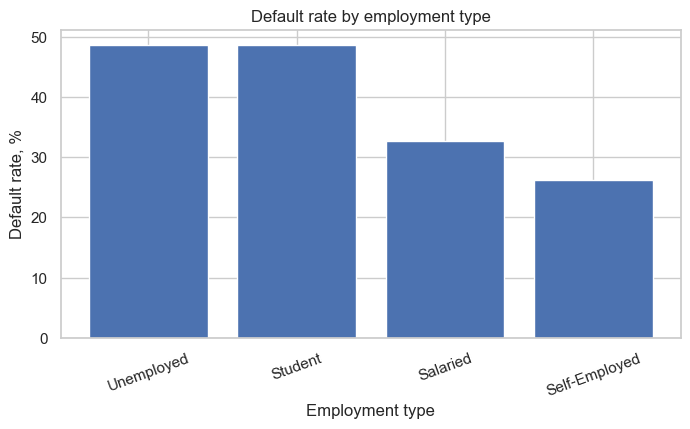

In [35]:
# Comparison 2: default rate by employment type

employment_default = (
    df_clean
    .groupby('employment_type')['default_flag']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
)

employment_default['mean'] = employment_default['mean'] * 100

employment_default = employment_default.rename(
    columns={
        'count': 'n_customers',
        'mean': 'default_rate_%'
    }
)

display(employment_default.round(2))

plt.figure(figsize=(8, 4))
plt.bar(employment_default.index, employment_default['default_rate_%'])
plt.title('Default rate by employment type')
plt.xlabel('Employment type')
plt.ylabel('Default rate, %')
plt.xticks(rotation=20)
plt.show()

* The default rate differs across employment types. Unemployed customers and students have a higher percentage of defaults than salaried and self-employed customers. This means that employment type is worth checking in the hypothesis section.

,number_of_customers,default_rate_%
location,,
Germany,1760,40.28
UK,1664,39.54
Australia,1722,38.91
Canada,1740,38.79
USA,1736,38.71
India,1723,38.07


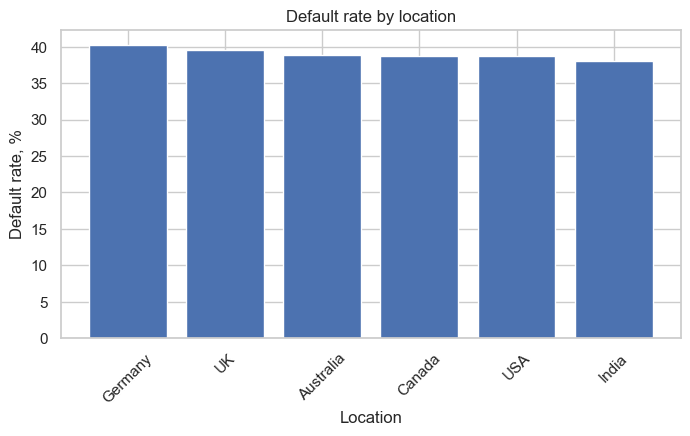

In [36]:
# Comparison 3: default rate by location

location_default = (
    df_clean
    .groupby('location')['default_flag']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
)

location_default['mean'] = location_default['mean'] * 100

location_default = location_default.rename(
    columns={
        'count': 'number_of_customers',
        'mean': 'default_rate_%'
    }
)

display(location_default.round(2))

plt.figure(figsize=(8, 4))
plt.bar(location_default.index, location_default['default_rate_%'])
plt.title('Default rate by location')
plt.xlabel('Location')
plt.ylabel('Default rate, %')
plt.xticks(rotation=45)
plt.show()

* The default rate differs across locations, but the difference is not very large. The gap between the highest and lowest locations is less than 5 percentage points.

,number_of_customers,default_rate_%
product_category,,
Fashion,2166,41.04
Home,2052,39.47
Electronics,2085,38.99
Beauty,2072,37.93
Sports,1970,37.66


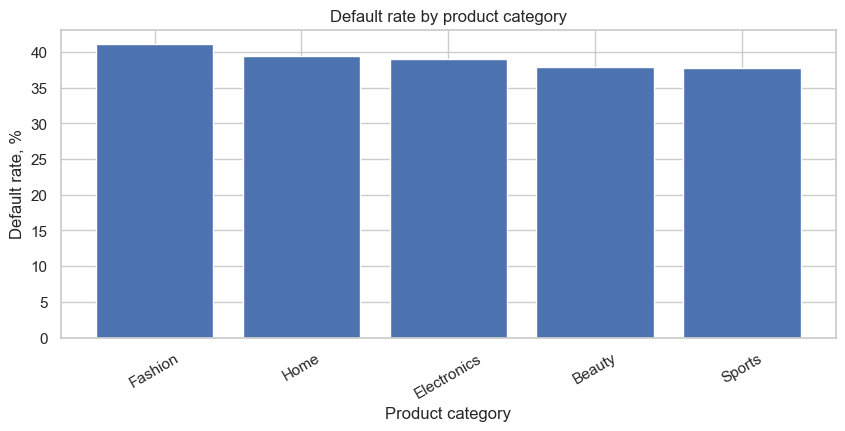

In [37]:
# Comparison 4: default rate by product category

category_default = (
    df_clean
    .groupby('product_category')['default_flag']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
)

category_default['mean'] = category_default['mean'] * 100

category_default = category_default.rename(
    columns={
        'count': 'number_of_customers',
        'mean': 'default_rate_%'
    }
)

display(category_default.round(2))

plt.figure(figsize=(10, 4))
plt.bar(category_default.index, category_default['default_rate_%'])
plt.title('Default rate by product category')
plt.xlabel('Product category')
plt.ylabel('Default rate, %')
plt.xticks(rotation=30)
plt.show()

* The bar chart shows that product categories have similar default rates. The differences are small, so product category does not look like one of the strongest variables in this dataset.

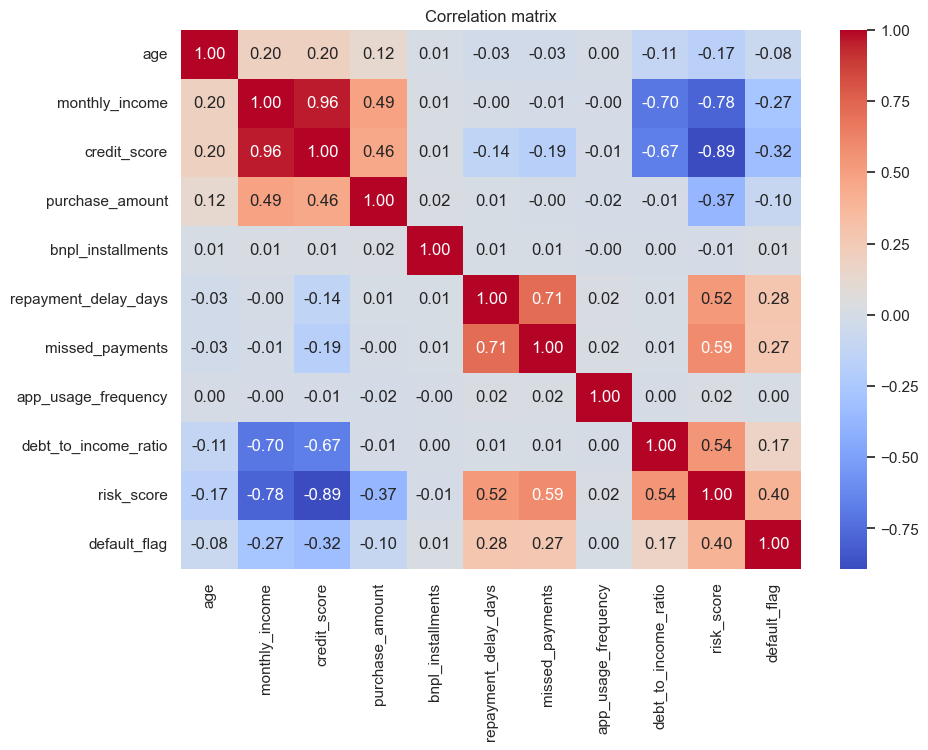

In [38]:
# Comparison 5: correlation matrix

corr_cols = [
    'age',
    'monthly_income',
    'credit_score',
    'purchase_amount',
    'bnpl_installments',
    'repayment_delay_days',
    'missed_payments',
    'app_usage_frequency',
    'debt_to_income_ratio',
    'risk_score',
    'default_flag'
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df_clean[corr_cols].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation matrix')
plt.show()

* The correlation matrix shows that `default_flag` has the strongest positive correlation with `risk_score` (0.40). It also has weaker positive correlations with `repayment_delay_days` (0.28), `missed_payments` (0.27), and `debt_to_income_ratio` (0.17).
At the same time, `default_flag` is negatively correlated with `credit_score` (-0.32) and `monthly_income` (-0.27). In this dataset, default is associated with higher risk scores, more delays, more missed payments, lower credit scores, and lower income.

In [39]:
# Comparison 6: numerical statistics by default flag
stats_by_default = df_clean.groupby('default_flag')[[
    'monthly_income',
    'credit_score',
    'purchase_amount',
    'repayment_delay_days',
    'missed_payments',
    'debt_to_income_ratio',
    'risk_score'
]].agg(['mean', 'median', 'std']).round(2)

display(stats_by_default)

monthly_income                     credit_score                 \
                       mean    median       std         mean median     std   
default_flag                                                                  
0                  40997.08  36973.99  29320.00       483.61  458.0  147.71   
1                  25777.39  17654.47  19893.19       392.88  367.0   93.05   

             purchase_amount                  repayment_delay_days         \
                        mean  median      std                 mean median   
default_flag                                                                
0                    4097.03  5000.0  1450.88                 7.21    6.0   
1                    3795.83  5000.0  1558.16                11.14   12.0   

                   missed_payments              debt_to_income_ratio         \
               std            mean median   std                 mean median   
default_flag                                                                  
0             5.96            0.80    1.0  0.82                 0.16   0.11   
1             7.27            1.35    1.0  1.14                 0.21   0.19   

                   risk_score                
               std       mean median    std  
default_flag                                 
0             0.12     176.94  184.4  67.72  
1             0.12     232.23  232.8  51.59

* This table compares numerical characteristics of clients with and without default. Clients with `default_flag = 1` tend to have higher `risk_score`, more repayment delays, more missed payments, and a higher debt-to-income ratio. At the same time, they usually have lower credit scores and monthly income.

**Detailed overview discussion**

The detailed overview shows that default is mainly associated with customer risk characteristics. The High Risk segment has the highest default rate, and unemployed customers and students also default more often.

Location and product category show only small differences, so they do not look like the strongest variables in this dataset.

The most important numerical variables in the comparisons are `risk_score`, `repayment_delay_days`, `missed_payments`, `credit_score`, and `monthly_income`. Clients with higher risk scores, more delays, and more missed payments have a higher default rate in this dataset, while higher credit score and income are connected with a lower default rate.

### 7. Data transformation

In this section, we create new columns to make the analysis more structured. We create transaction_month from transaction_date, age_group from age, income_group from monthly_income, and purchase_to_income_ratio from purchase_amount and monthly_income.


In [40]:
df_transformed = df_clean.copy()

# Create a month column from the date in a simple year-month format.
df_transformed['transaction_month'] = df_transformed['transaction_date'].astype(str).str[:7]

# Create age groups.
df_transformed['age_group'] = pd.cut(
    df_transformed['age'],
    bins=[0, 24, 34, 44, 54, 100],
    labels=['18-24', '25-34', '35-44', '45-54', '55+']
)

# Create income groups using quartile borders.
income_q1 = df_transformed['monthly_income'].quantile(0.25)
income_q2 = df_transformed['monthly_income'].quantile(0.50)
income_q3 = df_transformed['monthly_income'].quantile(0.75)
income_max = df_transformed['monthly_income'].max()

df_transformed['income_group'] = pd.cut(
    df_transformed['monthly_income'],
    bins=[0, income_q1, income_q2, income_q3, income_max],
    labels=['low income', 'medium-low income', 'medium-high income', 'high income'],
    include_lowest=True
)

# Create purchase-to-income ratio.
df_transformed['purchase_to_income_ratio'] = (
    df_transformed['purchase_amount'] / df_transformed['monthly_income']
)

display(df_transformed[[
    'transaction_date',
    'transaction_month',
    'age',
    'age_group',
    'monthly_income',
    'income_group',
    'purchase_amount',
    'purchase_to_income_ratio'
]].head())

,transaction_date,transaction_month,age,age_group,monthly_income,income_group,purchase_amount,purchase_to_income_ratio
0,2023-06-10,2023-06,56,55+,68529.50,high income,5000.00,0.072961
1,2024-10-07,2024-10,19,18-24,7247.85,low income,1073.23,0.148076
2,2023-04-05,2023-04,20,18-24,41582.26,medium-high income,5000.00,0.120244
3,2023-06-24,2023-06,21,18-24,14423.46,medium-low income,4076.83,0.282653
4,2024-10-19,2024-10,43,35-44,42845.50,medium-high income,5000.00,0.116698


In [41]:
# Check transformed columns

display(
    df_transformed[['age_group', 'income_group', 'transaction_month']]
    .describe()
)

display(
    df_transformed[['purchase_to_income_ratio']]
    .describe()
    .round(4)
)

,age_group,income_group,transaction_month
count,10345,10345,10345
unique,5,4,12
top,45-54,low income,2023-01
freq,2515,2587,899


,purchase_to_income_ratio
count,10345.0000
mean,0.1811
std,0.1249
min,0.0008
25%,0.0802
50%,0.1383
75%,0.2683
max,0.7235


**Data transformation discussion**

The new columns make the dataset easier to analyze. Age groups and income groups allow us to compare customers by broader categories. The transaction month can be used for time-based analysis. The purchase-to-income ratio compares purchase size with monthly income.

### 8. Hypothesis checking

This section checks three hypotheses. The hypotheses use filtered groups and combinations of variables, so they are more detailed than simple one-column comparisons.


**Hypothesis 1**

Hypothesis: among High Risk customers, those who have at least one missed payment have higher repayment delay than High Risk customers with no missed payments.

We first select only High Risk customers. Then we divide them into two groups: customers with missed payments and customers without missed payments. The main statistical test checks `repayment_delay_days`, while `default_rate` is also shown in the summary table as additional descriptive information.


,customers,default_rate,mean_delay,median_delay,mean_credit_score
has_missed_payment,,,,,
False,2535,39.25,1.72,1.0,403.41
True,5034,54.75,12.99,13.0,377.17


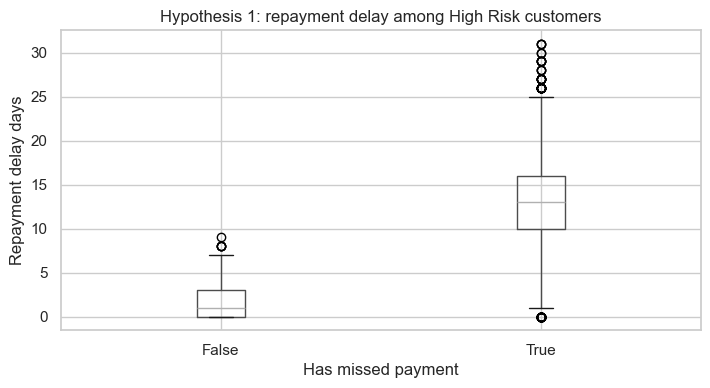

T-test for repayment delay:
t-statistic: 142.1031
p-value: 0.00e+00
Result: difference in repayment delay is statistically significant at 5% level.


In [42]:
high_risk = df_transformed[df_transformed['customer_segment'] == 'High Risk'].copy()
high_risk['has_missed_payment'] = high_risk['missed_payments'] > 0

hyp1_grouped = high_risk.groupby('has_missed_payment')

hyp1_table = pd.DataFrame({
    'customers': hyp1_grouped['user_id'].count(),
    'default_rate': hyp1_grouped['default_flag'].mean() * 100,
    'mean_delay': hyp1_grouped['repayment_delay_days'].mean(),
    'median_delay': hyp1_grouped['repayment_delay_days'].median(),
    'mean_credit_score': hyp1_grouped['credit_score'].mean()
})

display(hyp1_table.round(2))

high_risk.boxplot(
    column='repayment_delay_days',
    by='has_missed_payment',
    figsize=(8, 4)
)
plt.title('Hypothesis 1: repayment delay among High Risk customers')
plt.suptitle('')
plt.xlabel('Has missed payment')
plt.ylabel('Repayment delay days')
plt.show()

delay_with_missed = high_risk.loc[high_risk['has_missed_payment'], 'repayment_delay_days']
delay_without_missed = high_risk.loc[~high_risk['has_missed_payment'], 'repayment_delay_days']

t_stat, p_value = stats.ttest_ind(delay_with_missed, delay_without_missed, equal_var=False)

print('T-test for repayment delay:')
print('t-statistic:', round(t_stat, 4))
print('p-value:', format(p_value, '.2e'))

if p_value < 0.05:
    print('Result: difference in repayment delay is statistically significant at 5% level.')
else:
    print('Result: difference in repayment delay is not statistically significant at 5% level.')

* Hypothesis 1 discussion

The table and boxplot show that High Risk customers with missed payments have much higher repayment delays. The t-test checks whether this difference is statistically significant. The summary table also shows that default rate is higher for customers with missed payments, but this part is interpreted descriptively.


**Hypothesis 2**

Hypothesis: among customers with purchase amount at or above the median, customers with a high debt-to-income ratio have a higher risk score than customers with a low debt-to-income ratio.

This hypothesis focuses on large purchases and then compares two debt burden groups. We also look at default rate by customer segment and debt-to-income group as descriptive information. For the statistical test, we use a two-sample t-test for `risk_score`.


,customers,default_rate,mean_risk_score,median_risk_score,mean_debt_to_income_ratio
dti_group,,,,,
high DTI,2093,49.74,228.12,228.4,0.26
low DTI,3960,25.83,142.71,139.2,0.09


dti_group,high DTI,low DTI
customer_segment,,
High Risk,49.71,52.89
Low Risk,NaN,6.47
Medium Risk,53.85,7.99


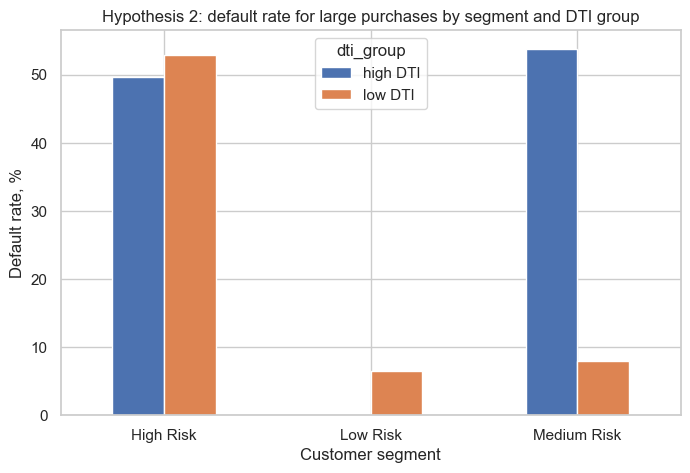

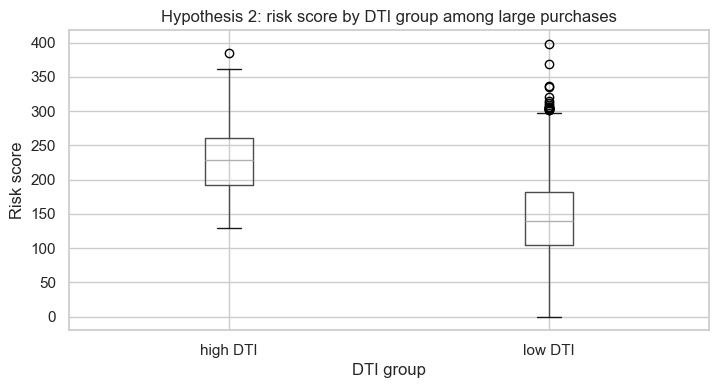

T-test for risk score:
t-statistic: 64.6083
p-value: 0.00e+00
Result: difference in risk score is statistically significant at 5% level.


In [43]:
df_hyp2 = df_transformed.copy()

purchase_median = df_hyp2['purchase_amount'].median()
dti_median = df_hyp2['debt_to_income_ratio'].median()

large_purchases = df_hyp2[df_hyp2['purchase_amount'] >= purchase_median].copy()
large_purchases['dti_group'] = np.where(
    large_purchases['debt_to_income_ratio'] > dti_median,
    'high DTI',
    'low DTI'
)

hyp2_grouped = large_purchases.groupby('dti_group')

hyp2_summary = pd.DataFrame({
    'customers': hyp2_grouped['user_id'].count(),
    'default_rate': hyp2_grouped['default_flag'].mean() * 100,
    'mean_risk_score': hyp2_grouped['risk_score'].mean(),
    'median_risk_score': hyp2_grouped['risk_score'].median(),
    'mean_debt_to_income_ratio': hyp2_grouped['debt_to_income_ratio'].mean()
})

display(hyp2_summary.round(2))

hyp2_segment_table = large_purchases.pivot_table(
    index='customer_segment',
    columns='dti_group',
    values='default_flag',
    aggfunc='mean'
) * 100

display(hyp2_segment_table.round(2))

hyp2_segment_table.plot(kind='bar', figsize=(8, 5))
plt.title('Hypothesis 2: default rate for large purchases by segment and DTI group')
plt.xlabel('Customer segment')
plt.ylabel('Default rate, %')
plt.xticks(rotation=0)
plt.show()

large_purchases.boxplot(
    column='risk_score',
    by='dti_group',
    figsize=(8, 4)
)
plt.title('Hypothesis 2: risk score by DTI group among large purchases')
plt.suptitle('')
plt.xlabel('DTI group')
plt.ylabel('Risk score')
plt.show()

risk_high_dti = large_purchases.loc[large_purchases['dti_group'] == 'high DTI', 'risk_score']
risk_low_dti = large_purchases.loc[large_purchases['dti_group'] == 'low DTI', 'risk_score']

t_stat, p_value = stats.ttest_ind(risk_high_dti, risk_low_dti, equal_var=False)

print('T-test for risk score:')
print('t-statistic:', round(t_stat, 4))
print('p-value:', format(p_value, '.2e'))

if p_value < 0.05:
    print('Result: difference in risk score is statistically significant at 5% level.')
else:
    print('Result: difference in risk score is not statistically significant at 5% level.')

* Hypothesis 2 discussion

This hypothesis checks whether debt burden is related to risk among customers with large purchases. The summary table compares high-DTI and low-DTI customers, and the bar chart shows default rates by customer segment and DTI group. The t-test checks whether the average `risk_score` differs significantly between high-DTI and low-DTI customers.


**Hypothesis 3**

Hypothesis: among customers with below-median credit score, risk score differs between students/unemployed customers and salaried/self-employed customers.

This hypothesis focuses only on customers whose credit score is already below the median. We compare employment groups and also show default rates by employment type and income group as descriptive information. For the statistical test, we use a two-sample t-test for `risk_score`.


income_group,low income,medium-low income,medium-high income,high income
employment_type,,,,
Salaried,40.00,48.96,60.87,NaN
Self-Employed,34.88,46.67,51.04,0.0
Student,48.22,50.35,55.36,NaN
Unemployed,48.15,50.76,50.00,NaN


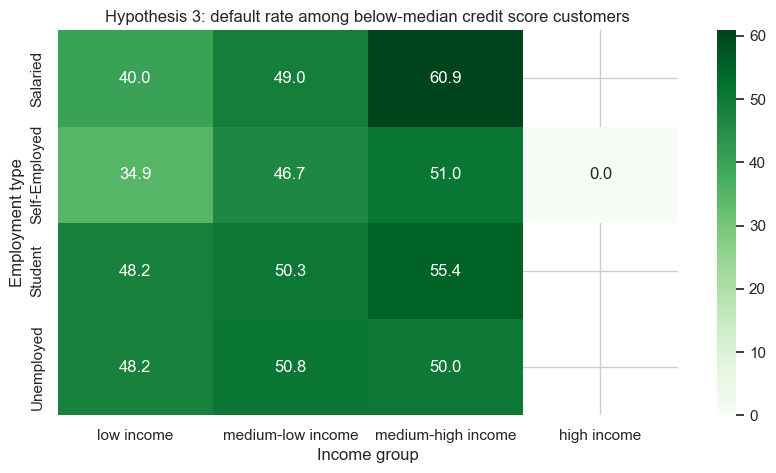

,customers,default_rate,mean_risk_score,median_risk_score,mean_delay
employment_risk_group,,,,,
Salaried or Self-Employed,482,51.24,251.31,252.0,11.46
Student or Unemployed,4688,49.38,246.60,248.4,9.15


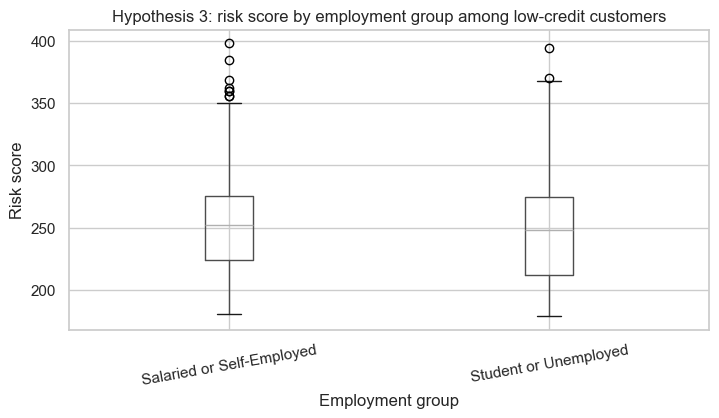

T-test for risk score:
t-statistic: -2.4925
p-value: 1.30e-02
Result: difference in risk score is statistically significant at 5% level.


In [44]:
credit_median = df_transformed['credit_score'].median()

low_credit = df_transformed[df_transformed['credit_score'] < credit_median].copy()

hyp3_table = low_credit.pivot_table(
    index='employment_type',
    columns='income_group',
    values='default_flag',
    aggfunc='mean',
    observed=False
) * 100

display(hyp3_table.round(2))

plt.figure(figsize=(10, 5))
sns.heatmap(hyp3_table, annot=True, fmt='.1f', cmap='Greens')
plt.title('Hypothesis 3: default rate among below-median credit score customers')
plt.xlabel('Income group')
plt.ylabel('Employment type')
plt.show()

low_credit['employment_risk_group'] = np.where(
    low_credit['employment_type'].isin(['Student', 'Unemployed']),
    'Student or Unemployed',
    'Salaried or Self-Employed'
)

hyp3_grouped = low_credit.groupby('employment_risk_group')

hyp3_summary = pd.DataFrame({
    'customers': hyp3_grouped['user_id'].count(),
    'default_rate': hyp3_grouped['default_flag'].mean() * 100,
    'mean_risk_score': hyp3_grouped['risk_score'].mean(),
    'median_risk_score': hyp3_grouped['risk_score'].median(),
    'mean_delay': hyp3_grouped['repayment_delay_days'].mean()
})

display(hyp3_summary.round(2))

low_credit.boxplot(
    column='risk_score',
    by='employment_risk_group',
    figsize=(8, 4)
)
plt.title('Hypothesis 3: risk score by employment group among low-credit customers')
plt.suptitle('')
plt.xlabel('Employment group')
plt.ylabel('Risk score')
plt.xticks(rotation=10)
plt.show()

risk_student_unemployed = low_credit.loc[
    low_credit['employment_risk_group'] == 'Student or Unemployed',
    'risk_score'
]
risk_other_employment = low_credit.loc[
    low_credit['employment_risk_group'] == 'Salaried or Self-Employed',
    'risk_score'
]

t_stat, p_value = stats.ttest_ind(
    risk_student_unemployed,
    risk_other_employment,
    equal_var=False
)

print('T-test for risk score:')
print('t-statistic:', round(t_stat, 4))
print('p-value:', format(p_value, '.2e'))

if p_value < 0.05:
    print('Result: difference in risk score is statistically significant at 5% level.')
else:
    print('Result: difference in risk score is not statistically significant at 5% level.')

* Hypothesis 3 discussion

This hypothesis checks whether employment status is related to risk among customers with below-median credit scores. The heatmap shows default rates by employment type and income group. The t-test checks whether students/unemployed customers and salaried/self-employed customers have different average `risk_score` values.


### 9. Final discussion

The analysis shows that the dataset is clean and suitable for exploratory analysis. The most important risk-related variables in this project are `customer_segment`, `risk_score`, `repayment_delay_days`, `missed_payments`, `credit_score`, and `debt_to_income_ratio`.

The transformed columns help us analyze dates, age, income, and purchase size more clearly. The hypothesis section uses filtered groups, summary tables, visualizations, and two-sample t-tests. This keeps the analysis close to the methods used in the workshops while still checking more detailed patterns in the data.

Overall, default rate is not equally distributed across customer segments. Repayment behavior variables are strongly associated with default. Debt-to-income ratio and purchase-to-income ratio help compare debt and purchase size with the customer's monthly income. Some categorical groups, such as employment type and customer segment, also show different default rates. These results should be interpreted as associations in this dataset, not as proof of direct cause-and-effect.